# Aerodynamics Assignment on Vortex Panel Method 
### BY: Naman Jain, SC26M013

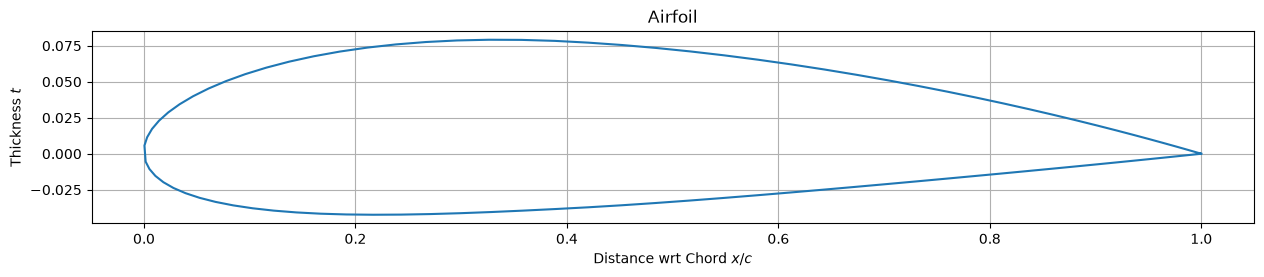

In [53]:
import numpy as np
import matplotlib.pyplot as plt

# Airfoil Plotting
a = 50    ## Number of points for plotting 
beta = np.linspace(0, np.pi, a)
x = 0.5 * (1 - np.cos(beta))

m = 2 / 100       # Maximum Camber
p = 4 / 10        # Location of Maximum Camber
t = 12 / 100     # Maximum Thickness

def airfoil_generation(x, m, p, t):
    x_u = np.zeros(len(x))
    x_l = np.zeros(len(x))
    y_u = np.zeros(len(x))
    y_l = np.zeros(len(x))
    y_t = np.zeros(len(x))
    y_c = np.zeros(len(x))
    dyc_dx = np.zeros(len(x))
    theta = np.zeros(len(x))
    
    #Original Airfoil Generation 
    for i in range(len(x)):
        y_t[i] = 5*t*(0.2969*(x[i]**0.5)        # Thickness distribution
                   - 0.1260*x[i]
                   - 0.3516*(x[i]**2)
                   + 0.2843*(x[i]**3)
                   - 0.1036*(x[i]**4))
    
        if 0 <= x[i] <= p:                      # Camber line and slope
            y_c[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
            dyc_dx[i] = (2*m / p**2) * (p - x[i])
    
        elif p < x[i] <= 1:
            y_c[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)
            dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])
            
        theta[i] = np.arctan(dyc_dx[i])         # Angle of camber line
        
        x_u[i] = x[i] - y_t[i]*np.sin(theta[i]) # Upper and lower surfaces
        x_l[i] = x[i] + y_t[i]*np.sin(theta[i])
        y_u[i] = y_c[i] + y_t[i]*np.cos(theta[i])
        y_l[i] = y_c[i] - y_t[i]*np.cos(theta[i])
        
    x_u[0] = 1.0
    x_l[0] = 1.0
    y_u[0] = 0.0
    y_l[0] = 0.0
        
    idx_u = np.argsort(x_u)
    idx_l = np.argsort(x_l)
    
    x_u, y_u = x_u[idx_u], y_u[idx_u]
    x_l, y_l = x_l[idx_l], y_l[idx_l]
    
    # Combine upper and lower surfaces
    x_full = np.concatenate((x_u[::-1], x_l))
    y_full = np.concatenate((y_u[::-1], y_l))
    
    return x_full, y_full

a = airfoil_generation(x, m, p, t)

plt.figure(figsize=(15, 2.5))
plt.plot(a[0], a[1])
plt.xlabel("Distance wrt Chord $x/c$")
plt.ylabel("Thickness $t$")
plt.title("Airfoil")
plt.grid(True)
plt.show()


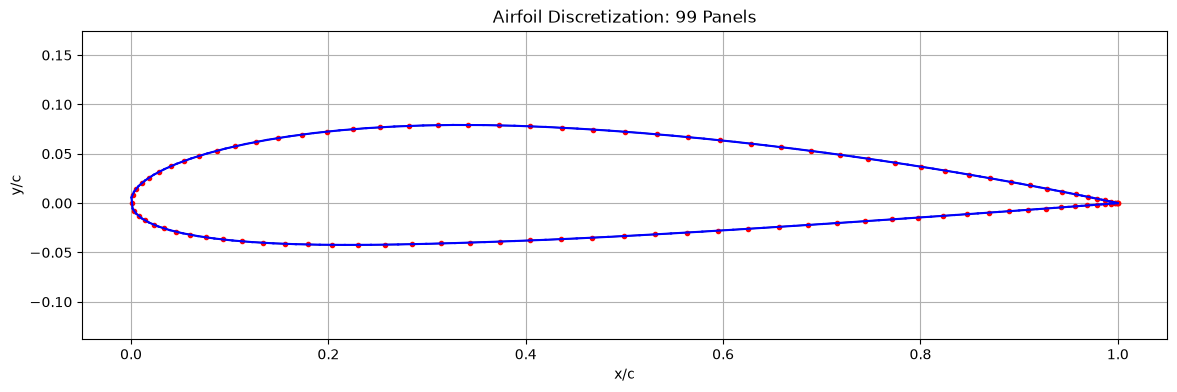

In [61]:
def panel_gen(x, y):
    x1 = x[:-1]
    y1 = y[:-1]
    x2 = x[1:]
    y2 = y[1:]

    N = len(x) - 1
    l = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    
    x_c = (x1 + x2)/2
    y_c1 = (y1 + y2)/2

    theta_p = np.arctan2((y2 - y1),(x2 - x1))
    normal_vector = np.array([np.sin(theta_p), -np.cos(theta_p)])
    
    return N, l, x_c, y_c1, theta_p, normal_vector, x1, x2, y1, y2

x_airfoil, y_airfoil = airfoil_generation(x, m, p, t)
N, l, x_c, y_c1, theta_p, normal_vector, x1, x2, y1, y2 = panel_gen(x_airfoil, y_airfoil)

# Plot panels and collocation points
plt.figure(figsize=(14, 4))
plt.plot(x_airfoil, y_airfoil, 'k-', linewidth=1)
plt.plot(x_c, y_c1, 'ro', markersize=3)

for i in range(N):
    plt.plot([x1[i], x2[i]], [y1[i], y2[i]], 'b-')
plt.axis('equal')
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f'Airfoil Discretization: {N} Panels')
plt.grid(True)
plt.show()

In [80]:
def gamma(N):
    gamma1 = np.zeros(N)
    return gamma1

def J_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2):
    J = np.zeros((N, N))
    for i in range(N):
        normal_vector0 = np.array([np.sin(theta_p[i]), - np.cos(theta_p[i])])
        for j in range(N):
            A_j = np.array([x1[j], y1[j]])
            P_i = np.array([x_c[i], y_c1[i]])

            tangent_vector1 = np.array([np.cos(theta_p[j]), np.sin(theta_p[j])])
            normal_vector1 = np.array([np.sin(theta_p[j]), - np.cos(theta_p[j])])

            x_ij = np.dot(P_i - A_j, tangent_vector1)
            y_ij = np.dot(P_i - A_j, normal_vector1)

            r1 = x_ij**2 + y_ij**2
            r2 = (x_ij - l[j])**2 + y_ij**2

            I1 = np.arctan2((l[j]*y_ij),(x_ij*(x_ij - l[j]) + y_ij**2))
            I2 = 0.5*np.log(r1/r2)

            J[i, j] = (np.dot(normal_vector0, tangent_vector1))*I1 - (np.dot(normal_vector0, normal_vector1))*I2

    return J

In [82]:
c = J_matrix(N, l, x_c, y_c1, theta_p, x1,x2,  y1, y2)
c

array([[-0.00000000e+00,  8.11114443e+00,  2.88985314e-01, ...,
        -1.07042642e-01, -8.66375444e-01,  1.09861229e+00],
       [-3.19649128e-14, -2.08832951e-13,  1.94470340e+00, ...,
         1.73394779e+00, -6.61576887e-01, -3.19417214e-14],
       [-6.39398286e-15, -5.11389047e-01,  0.00000000e+00, ...,
        -5.31589935e-01, -5.00115322e-01, -6.39398286e-15],
       ...,
       [ 6.39500194e-15,  5.00147164e-01,  5.31473246e-01, ...,
        -2.22044605e-16,  5.11414798e-01,  6.39500194e-15],
       [ 3.19510403e-14,  6.61526040e-01, -1.73420332e+00, ...,
        -1.94464832e+00, -2.13051798e-13,  3.19424536e-14],
       [-1.09861229e+00,  5.03885807e+00,  2.88985314e-01, ...,
        -1.07042642e-01, -3.99855779e+00, -0.00000000e+00]],
      shape=(99, 99))